**1   From Scripts to an Engine**

***3.1   The Body***


In [12]:
import numpy as np
import matplotlib.pyplot as plt

class Body:
    def __init__(self, mass, pos, vel, radius=0.1, I=None):
        self.m = mass
        self.r = np.array(pos, dtype=float)
        self.v = np.array(vel, dtype=float)
        self.radius = radius
        self.theta = 0.0      # orientation
        self.omega = 0.0      # angular velocity
        self.I = I if I is not None else 0.5*mass*radius**2
        self.force = np.zeros(2)   # accumulator, reset each step
        self.torque = 0.0

    def clear_accumulators(self):
        self.force = np.zeros(2)
        self.torque = 0.0

**3.2   Forces (the registry pattern)**


Each force is an object that knows how to apply itself to the bodies in the world. The world holds a list of them, so adding gravity, drag, or a spring is just appending to that list.

In [4]:
class Gravity:
    def __init__(self, g=9.81):
        self.g = np.array([0.0, -g])
    def apply(self, world):
        for b in world.bodies:
            b.force += b.m * self.g        # F = mg

class Drag:
    def __init__(self, c):
        self.c = c
    def apply(self, world):
        for b in world.bodies:
            b.force += -self.c * np.linalg.norm(b.v) * b.v   # quadratic drag

**3.3   The Integrator (swappable)**

In [5]:
class EulerCromer:
    def step(self, world, dt):
        for b in world.bodies:
            a = b.force / b.m
            b.v += a * dt
            b.r += b.v * dt
            alpha = b.torque / b.I
            b.omega += alpha * dt
            b.theta += b.omega * dt

**3.4   The World (ties it together)**

In [6]:
class World:
    def __init__(self, integrator):
        self.bodies = []
        self.forces = []
        self.integrator = integrator
        self.time = 0.0

    def add_body(self, body):  self.bodies.append(body)
    def add_force(self, force): self.forces.append(force)

    def step(self, dt):
        for b in self.bodies:
            b.clear_accumulators()
        for f in self.forces:
            f.apply(self)                 # each force adds to body accumulators
        self.integrator.step(self, dt)    # advance state
        self.handle_collisions()          # detect + resolve
        self.time += dt

    def handle_collisions(self):
        pass   # fill in using your Lab 4 collision code

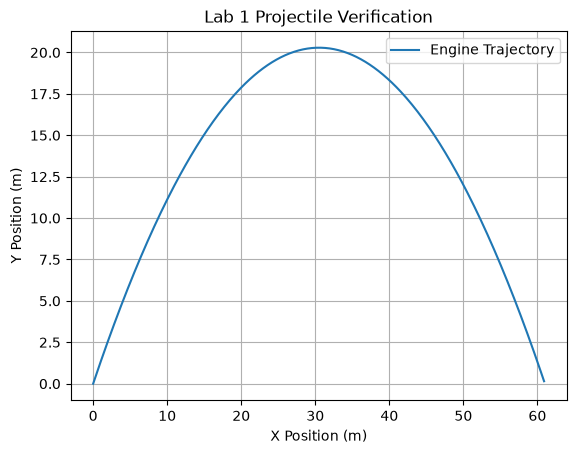

In [ ]:
# 1. Setup the engine components in the requested format
world = World(EulerCromer())
body = Body(mass=1, pos=[0, 0], vel=[15, 20])
world.add_body(body)
world.add_force(Gravity())

# 2. Setup lists to record your data
positions = []
times = []

# 3. Loop the engine step and record the position data
dt = 0.01
while body.r[1] >= 0:  # Runs until the projectile hits the ground (y < 0)
    positions.append(body.r.copy())  # .copy() ensures you don't store references
    times.append(world.time)
    world.step(dt)

# Convert to numpy array for clean indexing
positions = np.array(positions)

# 4. Optional: Quick visualization to verify against Lab 1
plt.plot(positions[:, 0], positions[:, 1], label="Engine Trajectory")
plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Lab 1 Projectile Verification")
plt.grid(True)
plt.legend()
plt.show()
